In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

import testis_model as tm

In [2]:
plt.rcParams.update({
    'font.family': 'Arial',
    'font.size': 12,              # base font size
    'xtick.labelsize': 7,        # x-axis tick label size
    'ytick.labelsize': 7,        # y-axis tick label size
    'axes.labelsize': 12,         # axis label size
    'axes.titlesize': 12,         # title size
    'legend.fontsize': 12,        # legend font size
    'figure.titlesize': 12        # figure title size
})

In [3]:
importlib.reload(tm.gillespie)

<module 'testis_model.gillespie' from '/Users/connor/Documents/github/sperm-data-analysis/testis_model/gillespie.py'>

In [4]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 0,
    q_div = 0,
    r_decay = 0,
    sperm_per_diff = 1300
)

rng = np.random.default_rng(1)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)
hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples1, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples1);

In [5]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 0.1,
    q_div = 0.1,
    r_decay = 0,
    sperm_per_diff = 1300
)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples2, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples2);

In [6]:
params = dict(
    n_stem = 1000,
    n_clones = 10,
    r_event = 36,
    p_diff = 0.25,
    q_div = 0.25,
    r_decay = 0,
    sperm_per_diff = 1300
)

init_freq = tm.gillespie.sample_ic(params['n_stem'], params['n_clones'], rng)

hmm = tm.gillespie.AdvancedTestisModel(**params, init_freq = init_freq)

sample_times = np.arange(1, 16)
n_sperm = 500

samples3, _, _ = hmm.simulate_gillespie(sample_times, n_sperm = n_sperm, rng = rng)
tm.data_processing.sort_results(samples3);

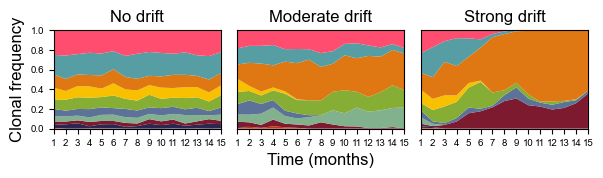

In [7]:
fig, ax = plt.subplots(1, 3, figsize = (6, 1.75))
tm.visualize.plot(samples1, ax = ax[0]);
ax[0].set_title('No drift')
ax[0].set_xlabel('')

tm.visualize.plot(samples2, ax = ax[1]);
ax[1].set_title('Moderate drift')
ax[1].set_xlabel('Time (months)')
ax[1].set_ylabel('')
ax[1].set_yticks([])

tm.visualize.plot(samples3, ax = ax[2]);
ax[2].set_title('Strong drift')
ax[2].set_xlabel('')
ax[2].set_ylabel('')
ax[2].set_yticks([])

fig.tight_layout(pad=0.5)
fig.savefig('./images/sample_sims.svg', bbox_inches='tight', format='svg')